# 07 — SVR: Support Vector Regression

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Modelo de suporte vetorial para regressão

---
### O que é o SVR (seção 2.4 da dissertação)

O SVR busca uma função que aproxime os dados dentro de uma **margem de tolerância ε**,
minimizando a complexidade da função (regularização C). Pontos fora da margem são
penalizados — os que ficam exatamente na fronteira são os **vetores de suporte**.

**Por que SVR é candidato relevante para cenários adversos:**
- Regularização explícita via C e ε → controla overfitting mesmo com poucos dados
- Kernel RBF captura não-linearidades sem especificação funcional
- Custo computacional escala com n_amostras — vantajoso em séries curtas

### Hiperparâmetros principais
| Parâmetro | Papel |
|---|---|
| `C` | Penalização de erros fora da margem — maior C = menos regularização |
| `epsilon` | Largura da margem de tolerância — pontos dentro não penalizam |
| `kernel` | Tipo de função de similaridade — RBF para não-linearidades |
| `gamma` | Raio de influência de cada ponto (kernel RBF) |

### Engenharia de features
**Idêntica aos notebooks 05 e 06** — mesmos lags, roll_mean, roll_std e lags sazonais.
Adicionalmente, o SVR requer **normalização** das features (StandardScaler) porque
é sensível à escala, ao contrário dos modelos baseados em árvores.

## 1. Imports e configurações

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')

import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import (
    DATA_DIR,
    H,
    MIN_TRAIN,
    N_ORIGINS,
    PILOT_N,
    PROJECT_ROOT,
    RESULT_DIR,
    SEASON,
    SEED,
    verify_data_files,
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)
verify_data_files()
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

# ── Configuração do SVR ───────────────────────────────────────────────────────
N_LAGS  = 12
SVR_C   = 1.0      # regularização
SVR_EPS = 0.1      # margem de tolerância
SVR_KERNEL = 'rbf' # kernel de base radial
SVR_GAMMA  = 'scale'  # gamma = 1 / (n_features * X.var())

np.random.seed(SEED)
print('Configuração carregada OK')
print(f'  Lags    : {N_LAGS}')
print(f'  C       : {SVR_C}')
print(f'  epsilon : {SVR_EPS}')
print(f'  kernel  : {SVR_KERNEL}')
print(f'  gamma   : {SVR_GAMMA}')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK
  Lags    : 12
  C       : 1.0
  epsilon : 0.1
  kernel  : rbf
  gamma   : scale


## 2. Funções base (pipeline padrão)

In [5]:
from src.m4_io import load_m4_monthly, sample_pilot_ids

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [6]:
import sys
from pathlib import Path

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import DATA_DIR, PILOT_N, SEED
from src.m4_io import load_m4_monthly, sample_pilot_ids

pilot_ids = sample_pilot_ids(DATA_DIR, PILOT_N, SEED)
train_df, test_df = load_m4_monthly(DATA_DIR, series_ids=pilot_ids)
train_pilot = train_df.copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas train | {len(test_df):,} linhas test')

Piloto: 200 séries | 42,600 linhas train | 3,600 linhas test


## 4. Engenharia de features (idêntica ao RF/GBT)

**Diferença importante vs RF/GBT:** o SVR requer normalização das features.
O `StandardScaler` é encapsulado em um `Pipeline` junto com o SVR — isso garante
que o scaler seja ajustado **apenas no treino** e aplicado ao teste sem vazamento de dados.

In [7]:
def build_features(series, n_lags=N_LAGS, season=SEASON):
    """
    Idêntica aos notebooks 05 e 06.
    Features: lag_1..lag_L, roll_mean, roll_std, lag_season, lag_season2
    """
    n = len(series)
    lag_cols = {f'lag_{i}': np.full(n, np.nan) for i in range(1, n_lags+1)}
    for i in range(1, n_lags+1):
        lag_cols[f'lag_{i}'][i:] = series[:-i]

    df = pd.DataFrame(lag_cols)
    df['roll_mean'] = df[[f'lag_{i}' for i in range(1, n_lags+1)]].mean(axis=1)
    df['roll_std']  = df[[f'lag_{i}' for i in range(1, n_lags+1)]].std(axis=1)
    df['lag_season']  = np.nan
    df['lag_season2'] = np.nan
    if n > season:
        df.loc[season:, 'lag_season'] = series[:-season]
    if n > 2*season:
        df.loc[2*season:, 'lag_season2'] = series[:-2*season]
    df['y'] = series

    feature_cols = [f'lag_{i}' for i in range(1, n_lags + 1)] + [
        'roll_mean', 'roll_std', 'lag_season',
    ]
    if n > 2 * season:
        feature_cols.append('lag_season2')

    df = df.dropna(subset=feature_cols)
    X = df[feature_cols].values
    y = df['y'].values
    return X, y, feature_cols


def predict_recursive_svr(pipeline, scaler_y, train, horizon,
                           n_lags=N_LAGS, season=SEASON, feature_cols=None):
    """
    Previsão recursiva com SVR.
    O pipeline (scaler + SVR) já está ajustado no espaço normalizado.
    A previsão é des-normalizada antes de entrar no histórico.
    """
    if feature_cols is None:
        _, _, feature_cols = build_features(train, n_lags, season)

    use_lag2 = 'lag_season2' in feature_cols
    history = list(train.copy())
    preds   = []

    for _ in range(horizon):
        n = len(history)
        lags = [history[n - i] for i in range(1, n_lags + 1)]
        roll_mean = float(np.mean(lags))
        roll_std  = float(np.std(lags, ddof=1)) if len(lags) > 1 else 0.0
        lag_s = history[n - season] if n >= season else history[0]

        feats = lags + [roll_mean, roll_std, lag_s]
        if use_lag2:
            lag_s2 = history[n - 2 * season] if n >= 2 * season else history[0]
            feats.append(lag_s2)

        x = np.array(feats, dtype=float).reshape(1, -1)

        # Prediz no espaço normalizado e des-normaliza
        pred_norm = pipeline.predict(x)[0]
        pred      = scaler_y.inverse_transform([[pred_norm]])[0][0]

        preds.append(pred)
        history.append(pred)

    return np.array(preds)


# Teste
ex = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 3).astype(float)
X_ex, y_ex, feat_names = build_features(ex)
print(f'Série {len(ex)} obs → {X_ex.shape[0]} amostras | {len(feat_names)} features')
print(f'Normalização necessária: X médio={X_ex.mean():.1f}, std={X_ex.std():.1f}')

Série 36 obs → 12 amostras | 16 features
Normalização necessária: X médio=103.7, std=25.8


## 5. Modelo SVR com Pipeline de normalização

O `Pipeline(StandardScaler → SVR)` garante que:
1. O scaler é ajustado **apenas nos dados de treino** de cada janela
2. Os dados de teste são transformados com os parâmetros do treino
3. Não há vazamento de informação entre treino e teste

In [8]:
def model_svr(train, horizon,
              n_lags=N_LAGS, season=SEASON,
              C=SVR_C, epsilon=SVR_EPS,
              kernel=SVR_KERNEL, gamma=SVR_GAMMA):
    """
    SVR com normalização de features e target.
    Pipeline: StandardScaler(X) → SVR
    Target y também é normalizado separadamente.
    Previsão recursiva com des-normalização a cada passo.
    """
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))

    X, y, feat_cols = build_features(train, n_lags, season)
    if len(X) < 2:
        return np.full(horizon, np.mean(train))

    # Normaliza y separadamente (SVR é sensível à escala do target)
    scaler_y = StandardScaler()
    y_norm   = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

    # Pipeline: scaler de X + SVR
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('svr',    SVR(C=C, epsilon=epsilon, kernel=kernel, gamma=gamma))
    ])
    pipe.fit(X, y_norm)

    return predict_recursive_svr(
        pipe, scaler_y, train, horizon, n_lags, season, feature_cols=feat_cols
    )


# Verificação
t0       = time.time()
ex_pred  = model_svr(ex, horizon=H)
print(f'SVR — previsão {H} passos em {time.time()-t0:.3f}s')
print(f'  {ex_pred.round(1)}')
print(f'  Constante? {np.allclose(ex_pred, ex_pred[0])}')

SVR — previsão 18 passos em 0.013s
  [100.9 105.8 110.1 114.3 119.1 121.7 118.8 114.  109.9 105.8 101.3  99.3
 102.5 106.6 110.2 113.6 117.1 118.2]
  Constante? False


## 6. Execução do pipeline

> **Tempo esperado**: 1–5 minutos para 200 séries.  
> SVR com kernel RBF tem custo O(n²) — rápido para séries curtas, mais lento para longas.

In [9]:
def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    records = []
    ids     = train_df['unique_id'].unique()
    total   = len(ids)
    for i, uid in enumerate(ids):
        if (i+1) % 50 == 0 or i == 0:
            print(f'  [{i+1}/{total}] {uid}')
        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)
        if not windows:
            records.append({'unique_id':uid,'model':model_name,'origin':None,
                            'n_train':None,'mape':None,'mae':None,'r2':None,
                            'exec_time_s':None,'status':'SKIP_SHORT'})
            continue
        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {str(e)[:80]}'
            records.append({
                'unique_id'  : uid, 'model': model_name,
                'origin'     : win['origin'], 'n_train': len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter()-t0,
                'status'     : status
            })
    return pd.DataFrame(records)


print(f'Rodando SVR em {PILOT_N} séries...')
t_start = time.time()

results_svr = run_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'svr',
    predict_fn = model_svr
)

elapsed = time.time() - t_start
ok_n    = (results_svr['status'] == 'OK').sum()
err_n   = results_svr['status'].str.startswith('ERROR', na=False).sum()
skip_n  = (results_svr['status'] == 'SKIP_SHORT').sum()

print(f'\nConcluído em {elapsed:.1f}s ({elapsed/60:.1f} min)')
print(f'  OK           : {ok_n} janelas')
print(f'  Erros        : {err_n}')
print(f'  Taxa sucesso : {100*ok_n/(ok_n+err_n+skip_n):.1f}%')

Rodando SVR em 200 séries...
  [1/200] M10288
  [50/200] M21209
  [100/200] M32071
  [150/200] M40980
  [200/200] M9633

Concluído em 6.3s (0.1 min)
  OK           : 600 janelas
  Erros        : 0
  Taxa sucesso : 100.0%


## 7. Resultados e comparação acumulada

In [10]:
ok_svr = results_svr[results_svr['status'] == 'OK'].copy()

by_series_svr = (
    ok_svr.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print('=== Desempenho SVR ===')
print(by_series_svr[['mape','mae','r2']].describe().round(3).to_string())
print(f'\nMAPE mediano = {by_series_svr["mape"].median():.4f}%')
print(f'MAE  mediano = {by_series_svr["mae"].median():.4f}')
print(f'R²   mediano = {by_series_svr["r2"].median():.4f}')
print(f'Tempo mediano= {by_series_svr["exec_time_s"].median():.4f}s')

# Tabela acumulada
prev_path = RESULT_DIR / 'tabela_acumulada_nb06_gbt.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0)
    svr_row = pd.DataFrame([{
        'MAPE (%)' : round(by_series_svr['mape'].median(), 4),
        'MAE'      : round(by_series_svr['mae'].median(),  4),
        'R²'       : round(by_series_svr['r2'].median(),   4),
        'Tempo (s)': round(by_series_svr['exec_time_s'].median(), 4),
    }], index=['SVR'])
    summary = pd.concat([prev, svr_row]).sort_values('MAPE (%)')
else:
    summary = pd.DataFrame([{
        'MAPE (%)' : round(by_series_svr['mape'].median(), 4),
        'MAE'      : round(by_series_svr['mae'].median(),  4),
        'R²'       : round(by_series_svr['r2'].median(),   4),
        'Tempo (s)': round(by_series_svr['exec_time_s'].median(), 4),
    }], index=['SVR'])

print('\n=== Comparação acumulada — todos os modelos ===')
print(summary.to_string())
summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb07_svr.csv')
print('\nTabela salva em results/tabela_acumulada_nb07_svr.csv')

=== Desempenho SVR ===
          mape       mae       r2
count  200.000   200.000  200.000
mean    18.136   677.083   -3.671
std     21.445   914.755    5.296
min      1.109    12.094  -30.793
25%      4.329   151.378   -4.823
50%     11.133   371.882   -1.500
75%     24.825   786.448   -0.291
max    171.716  7044.602    0.953

MAPE mediano = 11.1325%
MAE  mediano = 371.8824
R²   mediano = -1.5001
Tempo mediano= 0.0096s

=== Comparação acumulada — todos os modelos ===
                   MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters         8.2606  256.0183 -1.0642     0.1852
Persistência         8.6992  274.1667 -1.2684     0.0004
SES                  8.7764  253.5196 -1.1898     0.0038
SARIMA auto (AIC)    9.1184  266.3902 -1.2678     0.2127
Gradient Boosting    9.9031  321.6768 -1.1837     0.0477
SARIMA heurístico   10.0628  284.7858 -2.0551     0.0990
Random Forest       10.5861  341.6680 -1.0925     0.3364
Sazonal ingênuo     11.0601  316.8889 -2.1744     0.0004
SVR           

## 8. SVR vs modelos de árvore — comparação por família

Dado direto para a seção 2.4: *'em avaliações sistemáticas, o desempenho do SVR
tende a ser competitivo em séries com volume amostral limitado'*.

In [11]:
rf_path  = RESULT_DIR / 'results_rf_by_series.csv'
gbt_path = RESULT_DIR / 'results_gbt_by_series.csv'

if rf_path.exists() and gbt_path.exists():
    rf_df  = pd.read_csv(rf_path)
    gbt_df = pd.read_csv(gbt_path)

    comp = pd.DataFrame({
        'SVR'              : [by_series_svr['mape'].median(),
                              by_series_svr['mae'].median(),
                              by_series_svr['r2'].median(),
                              by_series_svr['exec_time_s'].median()],
        'Random Forest'    : [rf_df['mape'].median(),
                              rf_df['mae'].median(),
                              rf_df['r2'].median(),
                              rf_df['exec_time_s'].median()],
        'Gradient Boosting': [gbt_df['mape'].median(),
                              gbt_df['mae'].median(),
                              gbt_df['r2'].median(),
                              gbt_df['exec_time_s'].median()],
    }, index=['MAPE (%)', 'MAE', 'R²', 'Tempo (s)'])

    print('=== SVR vs modelos de árvore ===')
    print(comp.round(4).to_string())
    comp.to_csv(RESULT_DIR / 'comparacao_svr_vs_arvores.csv')

    # Por série — SVR melhor que GBT em quantas?
    merged = (
        by_series_svr[['unique_id','mape']].rename(columns={'mape':'mape_svr'})
        .merge(gbt_df[['unique_id','mape']].rename(columns={'mape':'mape_gbt'}), on='unique_id')
        .merge(rf_df[['unique_id','mape']].rename(columns={'mape':'mape_rf'}),  on='unique_id')
    )
    print(f'\nSVR melhor que GBT em {(merged["mape_svr"] < merged["mape_gbt"]).mean()*100:.1f}% das séries')
    print(f'SVR melhor que RF  em {(merged["mape_svr"] < merged["mape_rf"]).mean()*100:.1f}% das séries')
else:
    print('Arquivos RF/GBT não encontrados. Execute os notebooks 05 e 06 primeiro.')

=== SVR vs modelos de árvore ===
                SVR  Random Forest  Gradient Boosting
MAPE (%)    11.1325        10.5861             9.9031
MAE        371.8824       341.6680           321.6768
R²          -1.5001        -1.0925            -1.1837
Tempo (s)    0.0096         0.3364             0.0477

SVR melhor que GBT em 34.0% das séries
SVR melhor que RF  em 31.5% das séries


## 9. SVR em séries curtas — cenário adverso de insuficiência amostral

In [12]:
# Divide séries por comprimento e compara desempenho
lengths = train_pilot.groupby('unique_id')['y'].count()

curtas  = lengths[lengths < 80].index.tolist()
medias  = lengths[(lengths >= 80) & (lengths < 200)].index.tolist()
longas  = lengths[lengths >= 200].index.tolist()

print(f'Séries por comprimento:')
print(f'  Curtas  (< 80 obs) : {len(curtas)}')
print(f'  Médias  (80-199)   : {len(medias)}')
print(f'  Longas  (>= 200)   : {len(longas)}')

# Carrega modelos anteriores para comparação
modelos_comp = {'svr': by_series_svr}
for fname, mname in [
    ('results_rf_by_series.csv',  'random_forest'),
    ('results_gbt_by_series.csv', 'gbt'),
    ('results_nb02_by_series.csv', None),
]:
    path = RESULT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        if 'model' not in df.columns and mname:
            df['model'] = mname
        for m in df['model'].unique():
            if m in ['holt_winters', 'random_forest', 'gbt']:
                modelos_comp[m] = df[df['model']==m]

print('\nMAPE mediano por faixa de comprimento:')
print(f'{"Modelo":<20} {"Curtas":>10} {"Médias":>10} {"Longas":>10}')
print('-' * 52)
for nome, df in modelos_comp.items():
    m_c = df[df['unique_id'].isin(curtas)]['mape'].median()
    m_m = df[df['unique_id'].isin(medias)]['mape'].median()
    m_l = df[df['unique_id'].isin(longas)]['mape'].median()
    print(f'{nome:<20} {m_c:>10.2f} {m_m:>10.2f} {m_l:>10.2f}')

Séries por comprimento:
  Curtas  (< 80 obs) : 47
  Médias  (80-199)   : 55
  Longas  (>= 200)   : 98

MAPE mediano por faixa de comprimento:
Modelo                   Curtas     Médias     Longas
----------------------------------------------------
svr                       32.55      11.21       6.62
random_forest             29.84      10.68       6.36
gbt                       24.70       9.19       5.79
holt_winters              21.20       2.26       2.38


## 10. Boxplot comparativo acumulado — todos os modelos

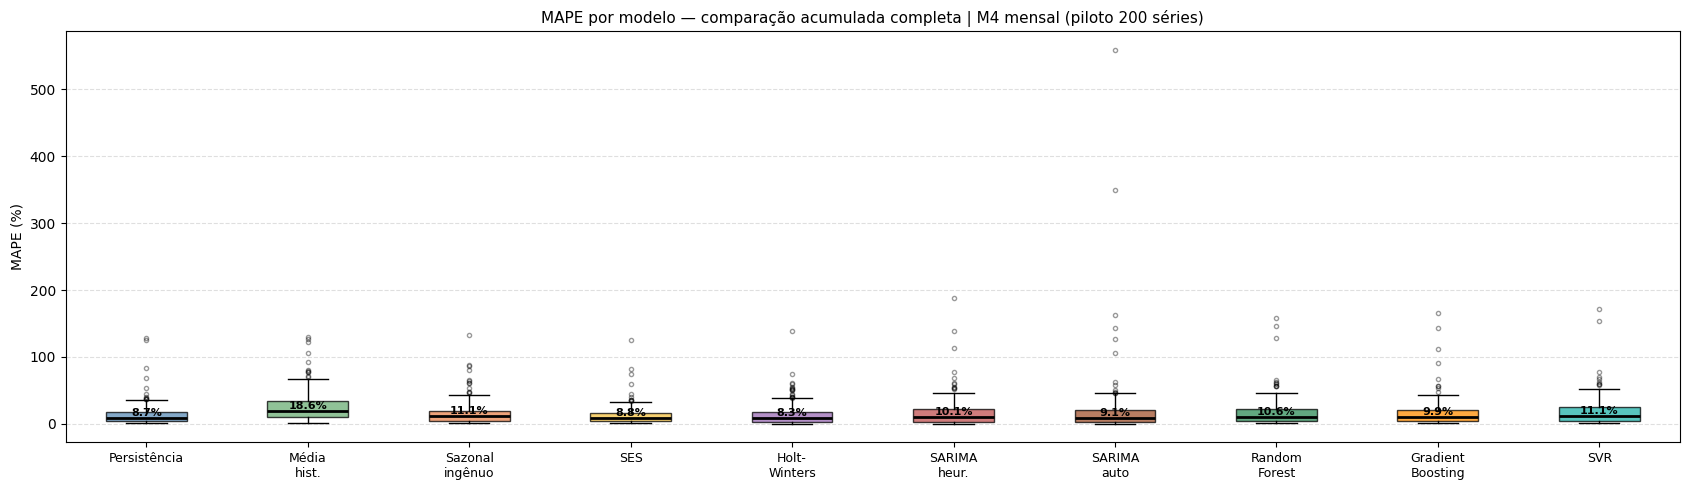

Figura final salva: fig_mape_acumulado_COMPLETO.png


In [13]:
dfs = []
for fname, model_col in [
    ('results_nb02_by_series.csv',             None),
    ('results_ses_by_series.csv',              'ses'),
    ('results_sarima_heuristic_by_series.csv', 'sarima_heuristic'),
    ('results_sarima_auto_by_series.csv',      'sarima_auto'),
    ('results_rf_by_series.csv',               'random_forest'),
    ('results_gbt_by_series.csv',              'gbt'),
]:
    path = RESULT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        if 'model' not in df.columns and model_col:
            df['model'] = model_col
        dfs.append(df)

svr_plot = by_series_svr.copy()
svr_plot['model'] = 'svr'
dfs.append(svr_plot)
all_df = pd.concat(dfs, ignore_index=True)

order_plot = ['persistence','mean','seasonal_naive','ses',
              'holt_winters','sarima_heuristic','sarima_auto',
              'random_forest','gbt','svr']
name_map   = {
    'persistence'     : 'Persistência',
    'mean'            : 'Média\nhist.',
    'seasonal_naive'  : 'Sazonal\ningênuo',
    'ses'             : 'SES',
    'holt_winters'    : 'Holt-\nWinters',
    'sarima_heuristic': 'SARIMA\nheur.',
    'sarima_auto'     : 'SARIMA\nauto',
    'random_forest'   : 'Random\nForest',
    'gbt'             : 'Gradient\nBoosting',
    'svr'             : 'SVR',
}
colors_plot = ['#5B8DB8','#6BAE75','#E8834E','#F5C242','#9B6BB5',
               '#C05050','#A0522D','#2E8B57','#FF8C00','#20B2AA']

order_present = [m for m in order_plot if m in all_df['model'].unique()]
data_list     = [all_df[all_df['model']==m]['mape'].dropna() for m in order_present]

fig, ax = plt.subplots(figsize=(17, 5))
bp = ax.boxplot(
    data_list, patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present)+1))
ax.set_xticklabels([name_map[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE por modelo — comparação acumulada completa | M4 mensal (piloto 200 séries)',
             fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.4)
for i, d in enumerate(data_list):
    ax.text(i+1, d.median(), f'{d.median():.1f}%',
            ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_mape_acumulado_COMPLETO.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura final salva: fig_mape_acumulado_COMPLETO.png')

## 11. Salvando artefatos

In [14]:
results_svr.to_csv(RESULT_DIR / 'results_svr_by_window.csv', index=False)
svr_plot.to_csv(RESULT_DIR / 'results_svr_by_series.csv', index=False)

run_log = {
    'timestamp'   : datetime.now().isoformat(),
    'notebook'    : '07_svr',
    'model'       : 'svr',
    'n_lags'      : N_LAGS,
    'C'           : SVR_C,
    'epsilon'     : SVR_EPS,
    'kernel'      : SVR_KERNEL,
    'gamma'       : SVR_GAMMA,
    'dataset'     : 'M4_Monthly',
    'pilot_n'     : PILOT_N,
    'seed'        : SEED,
    'horizon_H'   : H,
    'n_ok'        : int(ok_n),
    'n_errors'    : int(err_n),
    'taxa_sucesso': round(100*ok_n/(ok_n+err_n+skip_n), 2),
    'mape_median' : round(float(by_series_svr['mape'].median()), 4),
    'mae_median'  : round(float(by_series_svr['mae'].median()),  4),
    'r2_median'   : round(float(by_series_svr['r2'].median()),   4),
    'time_median_s': round(float(by_series_svr['exec_time_s'].median()), 4),
}

with open(RESULT_DIR / 'run_log_svr.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_svr_by_window.csv')
print('  results_svr_by_series.csv')
print('  run_log_svr.json')
print('  comparacao_svr_vs_arvores.csv')
print('  fig_mape_acumulado_COMPLETO.png')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_svr_by_window.csv
  results_svr_by_series.csv
  run_log_svr.json
  comparacao_svr_vs_arvores.csv
  fig_mape_acumulado_COMPLETO.png

{
  "timestamp": "2026-05-23T11:54:32.579014",
  "notebook": "07_svr",
  "model": "svr",
  "n_lags": 12,
  "C": 1.0,
  "epsilon": 0.1,
  "kernel": "rbf",
  "gamma": "scale",
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "n_ok": 600,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 11.1325,
  "mae_median": 371.8824,
  "r2_median": -1.5001,
  "time_median_s": 0.0096
}


## 12. Resumo e próximos passos

---

### Panorama completo dos modelos implementados

| Família | Modelos | Notebooks |
|---|---|---|
| Baselines ingênuos | Persistência, Média, Sazonal ingênuo | 01, 02 |
| Suavização exponencial | SES, Holt-Winters | 02, 03 |
| Modelos estatísticos | SARIMA heurístico, SARIMA auto | 04, 04b |
| Árvores de decisão | Random Forest, Gradient Boosting | 05, 06 |
| Suporte vetorial | SVR | 07 |

**Total: 10 modelos comparados** — todos os algoritmos previstos na dissertação. ✅

---

### Próximos notebooks — OE3 e OE4

**OE3 — Cenários adversos:**
- `08_cenarios_adversos.ipynb` — insuficiência amostral, ruído, ausências, anomalias
- Perturbações controladas sobre as séries do piloto
- Degradação de desempenho por modelo

**OE4 — Explicabilidade:**
- `09_shap.ipynb` — valores SHAP para RF e GBT (TreeSHAP)
- `10_lime.ipynb` — LIME para todos os modelos
- `11_explicabilidade_adversa.ipynb` — estabilidade das explicações sob perturbação